# Price of Activities for Context Model 

In [1]:
import pandas as pd 
import numpy as np

from scipy.sparse import csr_matrix
from implicit.bpr import BayesianPersonalizedRanking


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
metadata = pd.read_json(
    "../data/raw/meta-New_York.json.gz",
    lines=True,
    compression="gzip"
)

price_metadata = (
    metadata[["gmap_id", "price"]]
    .drop_duplicates(subset="gmap_id")
    .copy()
)

price_metadata.head()

,gmap_id,price
0,0x89c24469c758686b:0x641f5b84cb9bedfa,NaN
1,0x89c25fc9494dce47:0x6d63c807b59a55,$$
2,0x89c259992463b6e1:0x4a601a43752541dd,NaN
3,0x89d14bf74320aea5:0x720261cd8960f8cd,NaN
4,0x89d0bd8d2df8d10f:0x77a8f349f40492fa,NaN


## Import (current) activity filter

In [3]:
import re 
# activity filter 
activity_groups = {
    "Food & Drink": [
        "restaurant",
        "steakhouse", 
        "deli",
        "bagel",
        "bistro", 
        "diner",
        "pizzeria",
        "buffet",
        "food truck",

        "cafe",
        "bakery",
        "donut",
        "dessert",
        "ice cream",
        "gelato",
        "frozen yogurt",

        "coffee shop",
        "tea shop",
        "juice shop", 
        "smoothie shop",
        
        "bar",
        "cocktail bar",
        "sports bar",
        "winery",
        "brewery",
        "pub",
    ],

    "Arts & Culture": [
        "art museum",
        "history museum",
        "science museum",
        "museum",
        "art gallery",
        "exhibit",

        "movie theater",
        "theater",
        "theatre",
        "opera",
        "performing arts theater",

        "historical landmark",
        "historical site",
        "heritage",
        "monument",
        "theater company",
    ],

    "Outdoor & Nature": [
        "park",
        "beach",

        "botanical garden",
        "community garden",
        "nature preserve",
        "national park",
        "nature reserve",
        "state park",
        "water front",
        "garden",

        "hiking area",
        "trail",
        "scenic spot",
    ],

    "Shopping and Leisure": [
        "bookstore",
        "book store",
        "comic book store",
        "record store",

        "antique store",
        "vintage store",
        "thrift store",
        "flea market",

        "shopping center",
        "outlet mall",
    ],

    "Games & Activities": [
        "bowling alley",
        "escape room",
        "arcade",
        "video arcade",
        "billiards", 
        "billiard",
        "pool hall", 
        "miniature golf", 
        "mini golf", 
        "laser tag", 
        "go-kart track",
        "paintball center",
        "trampoline park", 
        "indoor playground",
        "amusement park",
        "amusement center",
        "playground",
        "orchard", 
    ],

    "Sports & Fitness" : [
        "tennis court",
        "basketball court",
        "soccer field",
        "baseball field",
        "volleyball court", 
        "pickleball court",
        "swimming pool",
        "golf course",
        "golf club",
        "ice skating rink",
        "sports complex",
        
        "yoga studio",
        "pilates studio", 
        "boxing gym", 
        "climbing gym",
        "rock climbing",
        "dance studio",
        "hiking",
    ],

    "Nightlife & Live Entertainment": [
        "night club",
        "nightclub",
        "comedy club",
        "dance club",
        "jazz club",

        "live music venue",
        "music venue",
        "concert hall",
        "karaoke bar",
        "karaoke venue", 
        "lounge",
        "bar",
        "pub",
        "cocktail bar",
        "sports bar",
    ],

    "Sightseeing & Attractions" : [
        "tourist attraction",
        "scenic spot",
        "observation deck",
        "monument",
        "landmark",
        "fountain",
        "historical landmark",
        "historic house", 
        "viewpoint",
        "lookout",
        "observation point",
        
        "zoo",
        "aquarium",
        "botanical garden",
        "theme park",
        "planetarium",
        "observatory",
    ],

    "Wellness & Relaxation" : [
        "spa",
        "day spa",
        "sauna",
        "massage spa",
        "massage therapist", 
        "wellness center",
        "meditation center",
        "float spa" 
    ]
}

exclusions = [
    "fitness center",
    "gymnastics center",

    "supermarket",
    "grocery store",
    "shopping mall",
    "convenience store",
    "fast food restaurant", 
    "butcher", 

    "rv park",
    "mobile home", 
    "recreational vehicle park",
    "parking",
    "parking lot",
    "parking garage",
    "car dealer",
    "auto repair",
    
    "dealer",
    "repair",
    "contractor",
    "supplier",
    "supply",
    "warehouse",
    "storage",
    "manufacturer",
    "wholesaler", 
    "distribution center",
    "garden center",
    "restaurant supply store",
    "food products supplier",
    "bakery equipment",
    "coffee wholesaler",

    "medical center",
    "medical clinic",
    "weight loss",
    "reflexologist", 
    "doctor",
    "dentist",
    "pharmacy",
    "clinic",
    "eyebrow bar", 
    "laser hair removal",
    "waxing hair removal service",
    "tattoo", 

    "office",
    "coworking",
    "business center",
    "conference center",
    "marketing agency",
    "entertainment agency", 
    "event planner", 

    "wedding venue",
    "banquet hall"    
]

chain_exclusions = [
    "starbucks",
    "dunkin",
    "tim hortons",
    "baskinrobbins",
    "carvel",
    "friendlys",  
    "subway",
    "subway restaurants", 
    "mcdonalds",
    "burger king",
    "wendys",
    "dominos pizza",
    "taco bell",
    "kfc",
    "chipotle mexican grill",
    "panera bread",
    "popeyes louisiana kitchen",
    "five guys",
    "shake shack",
    "chick-fil-a",
    "pizza hut",
    "auntie annes", 
    "pizza hut express", 
    "papa johns pizza",
    "little caesars pizza",
    "applebees grill bar",
    "kennedy fried chicken", 
    "arbys",
    "checkers",
    "ihop", 
    "dennys",
    "pret a manger", 
    "boston market",
    "tgi fridays",
    "le pain quotidien", 
    "buffalo wild wings",
    "cold stone creamery",
    "jersey mikes subs", 
    "kung fu tea", 
    "shake shack",
    "white castle",  
    "red lobster", 
    "olive garden italian restaurant", 
    "red mango", 
    "outback steakhouse", 
    "au bon pain", 
    "sweet green", 
    "chilis grill bar", 


    "sally beauty", 
    "planet fitness",
    "retro fitness",
    "la fitness", 
    "best buy", 
    "barnes and noble"
]

def is_chain(name):
    if not isinstance(name, str):
        return False

    name = name.lower().strip()

    return any(chain in name for chain in chain_exclusions)

def matches_keyword(text, keyword):
    text = text.lower()
    keyword = keyword.lower()

    pattern = r"\b" + re.escape(keyword) + r"\b"

    return re.search(pattern, text) is not None

def has_exclusion(categories):

    if not isinstance(categories, list):
        return False

    for category in categories:
        for term in exclusions:
            if matches_keyword(category, term):
                return True

    return False

def get_activity_groups(categories):

    if not isinstance(categories, list):
        return []

    matched_groups = []

    for group, keywords in activity_groups.items():

        for category in categories:

            if any(
                matches_keyword(category, keyword)
                for keyword in keywords
            ):
                matched_groups.append(group)
                break

    return matched_groups


def is_activity(name, categories):

    if not isinstance(categories, list):
        return False

    if has_exclusion(categories):
        return False

    if is_chain(name):
        return False 
    
    return len(get_activity_groups(categories)) > 0


In [4]:
metadata["is_activity"] = metadata.apply(
    lambda row: is_activity(row["name"], row["category"]),
    axis=1
)

metadata["activity_groups"] = metadata["category"].apply(get_activity_groups)

## Check for missing price data

In [5]:
activities = metadata[metadata["is_activity"]]

print("Total activities:", len(activities))
print("Missing price:", activities["price"].isna().sum())
print(
    "Percent missing:",
    activities["price"].isna().mean() * 100
)

Total activities: 76561
Missing price: 41922
Percent missing: 54.75633808335837


In [6]:
price_missing_by_group = (
    activities
    .explode("activity_groups")
    .groupby("activity_groups")["price"]
    .apply(lambda x: x.isna().mean() * 100)
    .sort_values(ascending=False)
)

print(price_missing_by_group)

activity_groups
Sightseeing & Attractions         99.255358
Wellness & Relaxation             98.772468
Sports & Fitness                  98.571429
Outdoor & Nature                  98.405717
Arts & Culture                    97.043568
Games & Activities                93.532087
Shopping and Leisure              91.768455
Food & Drink                      40.082587
Nightlife & Live Entertainment    33.897367
Name: price, dtype: float64


## MF-BPR Model to generate candidate reccomendations

In [7]:
price_levels = {
    "$": 1,
    "$$": 2,
    "$$$": 3,
    "$$$$": 4
}

In [8]:
def get_budget_score(price, max_budget):
    if pd.isna(price):
        return 0.0

    price_level = price_levels.get(price)

    if price_level is None:
        return 0.0

    return 1.0 if price_level <= max_budget else -1.0

In [9]:
def budget_metrics(frame, max_budget, k=10):
    top = frame.head(k)

    known_price = top[
        top["price"].isin(price_levels.keys())
    ]

    known_count = len(known_price)

    if known_count == 0:
        return np.nan, 0

    matches = known_price["price"].apply(
        lambda price: price_levels[price] <= max_budget
    )

    match_rate = matches.mean()

    return match_rate, known_count

In [10]:
# load training interactions 
train_df = pd.read_csv(
    "../data/processed/train60.csv",
    dtype={
        "user_id": "string",
        "gmap_id": "string",
        "rating" : float
    },
    usecols=["user_id", "gmap_id", "rating"]
)

train_df = train_df.drop_duplicates(
    ["user_id", "gmap_id"]
)

positive_train = train_df[
    train_df["rating"] >= 4
].copy()

In [11]:
#encode users and activities 
user_indices, unique_users = pd.factorize(
    positive_train["user_id"],
    sort=True
)

activity_indices, unique_activities = pd.factorize(
    positive_train["gmap_id"],
    sort=True
)

user_to_index = {
    user_id: index
    for index, user_id in enumerate(unique_users)
}

activity_to_index = {
    activity_id: index
    for index, activity_id in enumerate(unique_activities)
}

index_to_user = {
    index: user_id
    for index, user_id in enumerate(unique_users)
}

index_to_activity = {
    index: activity_id
    for index, activity_id in enumerate(unique_activities)
}

num_users = len(unique_users)
num_activities = len(unique_activities)

In [12]:
# Construct the sparse user–activity interaction matrix
user_activity_matrix = csr_matrix(
    (
        np.ones(len(train_df), dtype=np.float32),
        (user_indices, activity_indices)
    ),
    shape=(num_users, num_activities),
    dtype=np.float32
)

In [13]:
# Initialize the BPR model
bpr_model_60 = BayesianPersonalizedRanking(
    factors=64,
    learning_rate=0.01,
    regularization=0.001,
    iterations=50,
    random_state=42
)

# Train using the sparse interaction matrix
bpr_model_60.fit(
    user_activity_matrix,
    show_progress=True
)

100%|██████████| 50/50 [02:09<00:00,  2.59s/it, train_auc=94.95%, skipped=0.15%]


In [14]:
def recommend_bpr(user_id, k=10):

    user_idx = user_to_index[user_id]

    recommended_items, scores = bpr_model_60.recommend(
        userid=user_idx,
        user_items=user_activity_matrix[user_idx],
        N=k,
        filter_already_liked_items=True
    )

    return recommended_items, scores

In [15]:
import ast

activity_df = pd.read_csv(
    "../data/processed/activity_dataset.csv"
)

train_with_categories = positive_train.merge(
    activity_df[
        ["gmap_id", "name", "category", "activity_groups"]
    ],
    on="gmap_id",
    how="left"
)

train_with_categories["category"] = (
    train_with_categories["category"]
    .apply(
        lambda x: ast.literal_eval(x)
        if isinstance(x, str)
        else x
    )
)

train_with_categories["activity_groups"] = (
    train_with_categories["activity_groups"]
    .apply(
        lambda x: ast.literal_eval(x)
        if isinstance(x, str)
        else x
    )
)

place_metadata = (
    activity_df[
        ["gmap_id", "name", "category", "activity_groups"]
    ]
    .drop_duplicates("gmap_id")
    .copy()
)

for col in ["category", "activity_groups"]:
    place_metadata[col] = place_metadata[col].apply(
        lambda x: ast.literal_eval(x)
        if isinstance(x, str) and x.strip().startswith("[")
        else x
    )

In [16]:
def get_bpr_candidates(user_id, candidate_k=50):

    # Get BPR recommendations
    items, scores = recommend_bpr(
        user_id,
        k=candidate_k
    )

    candidates = pd.DataFrame({
        "gmap_id": [
            index_to_activity[i]
            for i in items
        ],
        "bpr_score": scores
    })

    # Keep original BPR ranking
    candidates["bpr_rank"] = (
        np.arange(len(candidates)) + 1
    )

    # Add activity metadata
    candidates = candidates.merge(
        place_metadata,
        on="gmap_id",
        how="left",
        validate="many_to_one"
    )

    # Normalize BPR scores
    min_score = candidates["bpr_score"].min()
    max_score = candidates["bpr_score"].max()

    if max_score > min_score:
        candidates["bpr_normalized"] = (
            (candidates["bpr_score"] - min_score)
            / (max_score - min_score)
        )
    else:
        candidates["bpr_normalized"] = 0.0

    return candidates

## sample users

In [17]:
sample_df = pd.read_csv(
    "../data/processed/validation_sample_1000_users.csv",
    dtype={
        "user_id": "string",
    }
)

validation_df = pd.read_csv(
    "../data/processed/validation20.csv",
        dtype={
        "user_id": "string",
        "gmap_id": "string",
        "rating": float
    }
)

validation_pos = validation_df[
    validation_df["rating"] >= 4
].copy()

relevant_by_user = (
    validation_pos
    .groupby("user_id")["gmap_id"]
    .apply(set)
    .to_dict()
)

evaluation_users = sample_df[
    sample_df["user_id"].isin(relevant_by_user)
]["user_id"].tolist()

In [18]:
interaction_counts = positive_train.groupby("user_id").size()

evaluation_users = [
    user_id
    for user_id in evaluation_users
    if (
        user_id in user_to_index
        and 7 <= interaction_counts.get(user_id, 0) <= 10
    )
]

print("Number of evaluation users:", len(evaluation_users))

Number of evaluation users: 306


In [19]:
np.random.seed(42)

simulated_user = {
    "user_id": np.random.choice(evaluation_users),
    "max_budget": "$"
}

max_budget = price_levels[
    simulated_user["max_budget"]
]

simulated_user

{'user_id': np.str_('108144711817910648647'), 'max_budget': '$'}

In [20]:
candidates = get_bpr_candidates(
    simulated_user["user_id"],
    candidate_k=50
)

candidates = candidates.merge(
    price_metadata,
    on="gmap_id",
    how="left"
)

candidates.head()

,gmap_id,bpr_score,bpr_rank,name,category,activity_groups,bpr_normalized,price
0,0x89d0818e789e35f9:0xf0a255e51bf3e60a,1.634729,1,Collegetown Bagels,[Bagel shop],[Food & Drink],1.000000,$$
1,0x89c258521b46d4b3:0xcfaff37223ae728b,1.423372,2,The Marshal,"[New American restaurant, American restaurant,...",[Food & Drink],0.413543,$$$
2,0x89dd95d31f3ec3e1:0x7d398c9224db3677,1.402727,3,Wm. Farmer and Sons,"[New American restaurant, Bar, Restaurant]",[Food & Drink],0.356258,$$
3,0x89d0818feabe7297:0xce7ce42c9231b9c4,1.382082,4,Carriage House Cafe,"[Cafe, Breakfast restaurant]",[Food & Drink],0.298974,$$
4,0x89c258c0f861dd65:0x9f7ad28f173e49d0,1.381057,5,Bohemian Spirit,[Czech restaurant],[Food & Drink],0.296131,$$


In [21]:
candidates["budget_score"] = (
    candidates["price"].apply(
        lambda price: get_budget_score(
            price,
            max_budget
        )
    )
)

candidates[
    ["name", "price", "bpr_normalized", "budget_score"]
].head(10)

,name,price,bpr_normalized,budget_score
0,Collegetown Bagels,$$,1.000000,-1.0
1,The Marshal,$$$,0.413543,-1.0
2,Wm. Farmer and Sons,$$,0.356258,-1.0
3,Carriage House Cafe,$$,0.298974,-1.0
4,Bohemian Spirit,$$,0.296131,-1.0
5,Kish-Kash,NaN,0.251383,0.0
6,Senza Gluten,$$,0.221863,-1.0
7,American Express Centurion Lounge,$,0.178024,1.0
8,Lupa,$$$,0.174093,-1.0
9,Indochine,$$$$,0.124171,-1.0


In [22]:
budget_weights = [0, 0.05, 0.1, 0.15, 0.2]

for weight in budget_weights:
    candidates[f"score_{weight}"] = (
        candidates["bpr_normalized"]
        + weight * candidates["budget_score"]
    )

In [23]:
bpr_top10_ids = set(
    candidates.sort_values(
        "bpr_rank"
    ).head(10)["gmap_id"]
)

results = []

for weight in budget_weights:

    ranked = candidates.sort_values(
        [f"score_{weight}", "bpr_rank"],
        ascending=[False, True]
    )

    top10 = ranked.head(10)

    match_rate, known_count = budget_metrics(
        ranked,
        max_budget,
        k=10
    )

    overlap = len(
        set(top10["gmap_id"]) & bpr_top10_ids
    ) / 10

    results.append({
        "budget_weight": weight,
        "budget_match_rate": match_rate,
        "known_price_count": known_count,
        "bpr_top10_overlap": overlap
    })

weight_results = pd.DataFrame(results)

weight_results

,budget_weight,budget_match_rate,known_price_count,bpr_top10_overlap
0,0.00,0.111111,9,1.0
1,0.05,0.333333,9,0.8
2,0.10,0.333333,9,0.8
3,0.15,0.444444,9,0.7
4,0.20,0.444444,9,0.7


In [24]:
np.random.seed(42)

test_users = np.random.choice(
    evaluation_users,
    size=min(50, len(evaluation_users)),
    replace=False
)

test_budgets = ["$", "$$", "$$$"]

In [25]:
all_results = []

for user_id in test_users:

    user_candidates = get_bpr_candidates(
        user_id,
        candidate_k=50
    )

    user_candidates = user_candidates.merge(
        price_metadata,
        on="gmap_id",
        how="left"
    )

    if len(user_candidates) < 10:
        continue

    bpr_top10_ids = set(
        user_candidates.sort_values(
            "bpr_rank"
        ).head(10)["gmap_id"]
    )

    for budget in test_budgets:

        max_budget = price_levels[budget]

        user_candidates["budget_score"] = (
            user_candidates["price"].apply(
                lambda price: get_budget_score(
                    price,
                    max_budget
                )
            )
        )

        for weight in budget_weights:

            user_candidates["adjusted_score"] = (
                user_candidates["bpr_normalized"]
                + weight * user_candidates["budget_score"]
            )

            ranked = user_candidates.sort_values(
                ["adjusted_score", "bpr_rank"],
                ascending=[False, True]
            )

            top10 = ranked.head(10)

            match_rate, known_count = budget_metrics(
                ranked,
                max_budget,
                k=10
            )

            overlap = len(
                set(top10["gmap_id"]) & bpr_top10_ids
            ) / 10

            affordable_count = (
                top10["price"]
                .map(price_levels)
                .le(max_budget)
                .sum()
            )

            all_results.append({
                "user_id": user_id,
                "budget": budget,
                "budget_weight": weight,
                "budget_match_rate": match_rate,
                "known_price_count": known_count,
                "affordable_count": affordable_count,
                "bpr_top10_overlap": overlap
            })

multiuser_results = pd.DataFrame(all_results)

multiuser_results.head()

,user_id,budget,budget_weight,budget_match_rate,known_price_count,affordable_count,bpr_top10_overlap
0,111679270882673893030,$,0.00,0.1,10,1,1.0
1,111679270882673893030,$,0.05,0.1,10,1,1.0
2,111679270882673893030,$,0.10,0.1,10,1,1.0
3,111679270882673893030,$,0.15,0.1,10,1,1.0
4,111679270882673893030,$,0.20,0.2,10,2,0.9


In [26]:
budget_summary = (
    multiuser_results
    .groupby(["budget", "budget_weight"])
    .agg(
        avg_budget_match=("budget_match_rate", "mean"),
        avg_known_price_count=("known_price_count", "mean"),
        avg_affordable_count=("affordable_count", "mean"),
        avg_bpr_overlap=("bpr_top10_overlap", "mean"),
        users_with_known_prices=("budget_match_rate", "count")
    )
    .reset_index()
)

budget_summary

,budget,budget_weight,avg_budget_match,avg_known_price_count,avg_affordable_count,avg_bpr_overlap,users_with_known_prices
0,$,0.00,0.257329,7.52,1.92,1.000,49
1,$,0.05,0.374814,7.42,2.64,0.910,49
2,$,0.10,0.485188,7.34,3.42,0.818,49
3,$,0.15,0.597328,7.50,4.24,0.744,49
4,$,0.20,0.659329,7.60,4.86,0.680,49
5,$$,0.00,0.937698,7.52,6.98,1.000,49
6,$$,0.05,0.949887,7.86,7.42,0.956,49
7,$$,0.10,0.956122,8.18,7.78,0.920,49
8,$$,0.15,0.968594,8.44,8.16,0.882,49
9,$$,0.20,0.980021,8.72,8.54,0.844,49


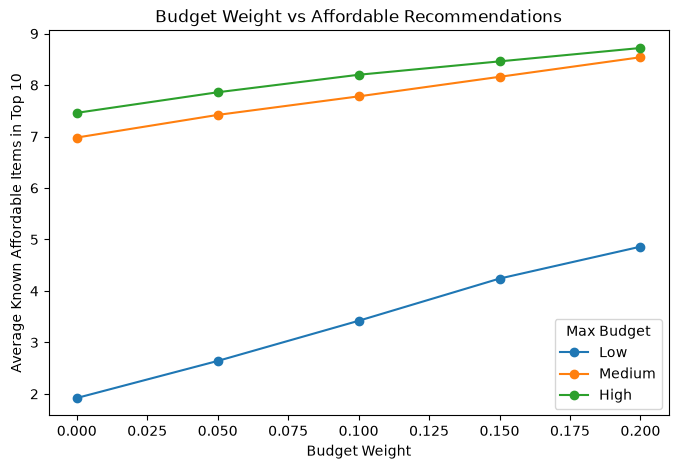

In [27]:
import matplotlib.pyplot as plt

budget_labels = {
    "$": "Low",
    "$$": "Medium",
    "$$$": "High"
}

plt.figure(figsize=(8, 5))

for budget in test_budgets:
    subset = budget_summary[
        budget_summary["budget"] == budget
    ]

    plt.plot(
        subset["budget_weight"],
        subset["avg_affordable_count"],
        marker="o",
        label=budget_labels[budget]
    )

plt.xlabel("Budget Weight")
plt.ylabel("Average Known Affordable Items in Top 10")
plt.title("Budget Weight vs Affordable Recommendations")
plt.legend(title="Max Budget")
plt.show()

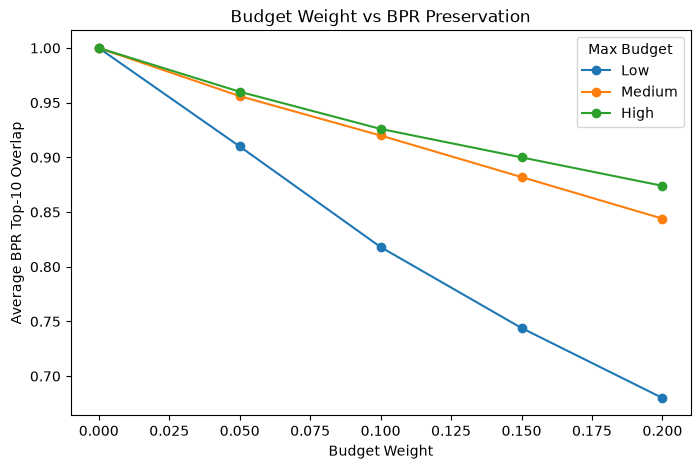

In [28]:
import matplotlib.pyplot as plt

budget_labels = {
    "$": "Low",
    "$$": "Medium",
    "$$$": "High"
}

plt.figure(figsize=(8, 5))

for budget in test_budgets:
    subset = budget_summary[
        budget_summary["budget"] == budget
    ]

    plt.plot(
        subset["budget_weight"],
        subset["avg_bpr_overlap"],
        marker="o",
        label=budget_labels[budget]
    )

plt.xlabel("Budget Weight")
plt.ylabel("Average BPR Top-10 Overlap")
plt.title("Budget Weight vs BPR Preservation")
plt.legend(title="Max Budget")
plt.show()

Preliminary weught: 0.1 for budget